In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [4]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [5]:
df.duplicated().sum()

np.int64(5268)

In [6]:
df = df.dropna(subset=["CustomerID"]).copy()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["InvoiceNo"].astype(str).str.upper().str.startswith("C"))
].copy()

df = df.drop_duplicates()

df["CustomerID"] = df["CustomerID"].astype(int)

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned dataset shape:", df.shape)
display(df.head())


Cleaned dataset shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [7]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
TotalPrice,0


In [8]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()


In [9]:
rfm.shape

(4338, 4)

In [10]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [11]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


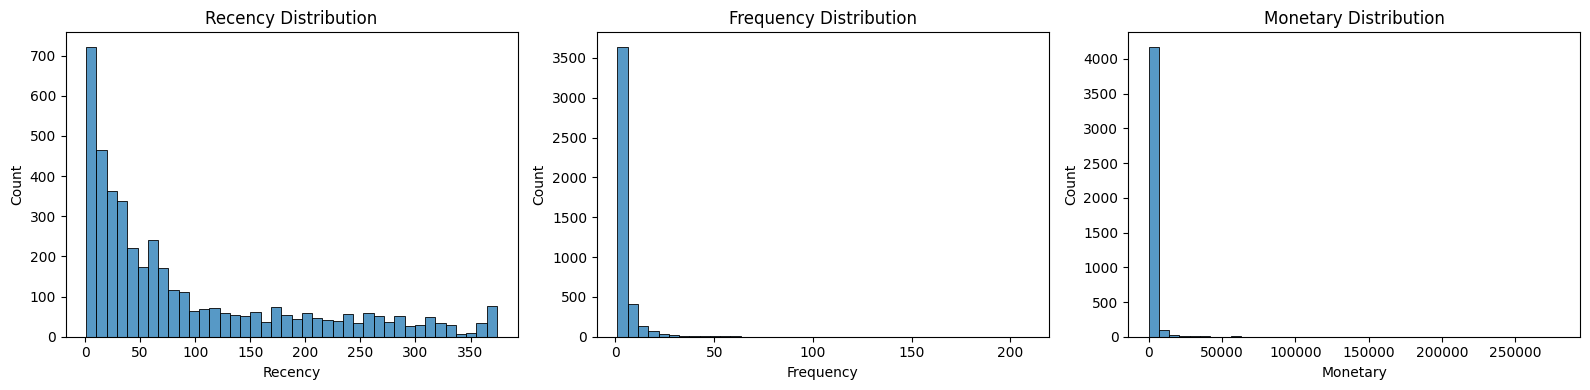

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(
    axes, ["Recency", "Frequency", "Monetary"]
):
    sns.histplot(rfm[column], bins=40, ax=ax)
    ax.set_title(f"{column} Distribution")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.preprocessing import StandardScaler

In [14]:
features = ["Recency", "Frequency", "Monetary"]

X = rfm[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

pd.DataFrame(X_scaled,columns=features).head()

Scaled data shape: (4338, 3)


,Recency,Frequency,Monetary
0,2.334574,-0.425097,8.363010
1,-0.905340,0.354417,0.251699
2,-0.175360,-0.035340,-0.027988
3,-0.735345,-0.425097,-0.032406
4,2.174578,-0.425097,-0.190812


KMeans Clustering

In [15]:
from sklearn.cluster import KMeans

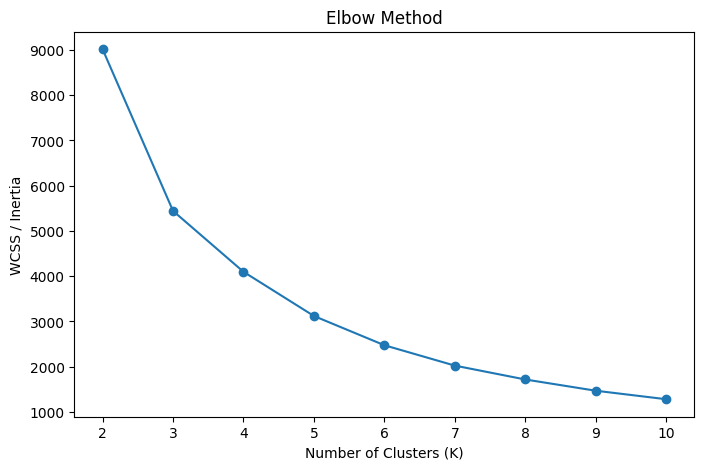

In [16]:
k_values = range(2, 11)
wcss = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.show()


In [17]:
from sklearn.metrics import silhouette_score

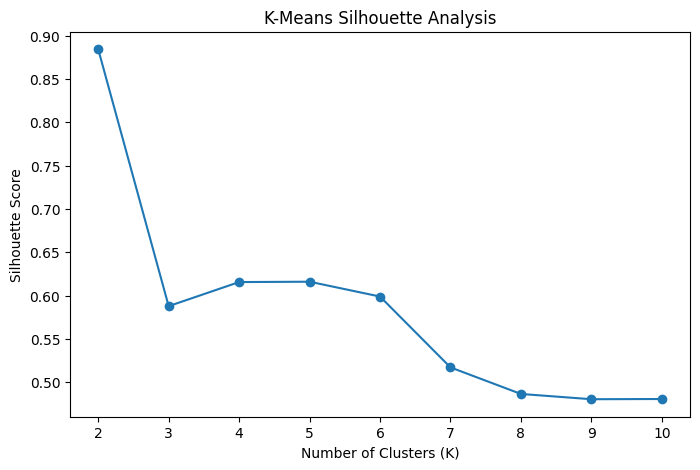

Best K by silhouette score: 2


In [18]:
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled, labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Analysis")
plt.xticks(list(k_values))
plt.show()

best_k = list(k_values)[np.argmax(silhouette_scores)]
print("Best K by silhouette score:", best_k)


In [19]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
print(rfm["KMeans_Cluster"].value_counts().sort_index())

print("\nCluster characteristics:")
display(
    rfm.groupby("KMeans_Cluster")[features]
    .agg(["mean", "median"])
    .round(2)
)


Cluster sizes:
KMeans_Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64

Cluster characteristics:


Recency        Frequency          Monetary           
                  mean median      mean median       mean     median
KMeans_Cluster                                                      
0                43.70   32.0      3.68    3.0    1353.63     826.27
1               248.08  243.0      1.55    1.0     478.85     310.26
2                 7.38    2.0     82.54   63.0  127187.96  117210.08
3                15.50    5.0     22.33   19.0   12690.50    7990.20

### Interactive 3D Visualization of K-Means Clusters (using Plotly)

In [20]:
import plotly.express as px

# Create 3D scatter plot for K-Means
fig_km = px.scatter_3d(
    rfm,
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    z=X_scaled[:, 2],
    color=rfm['KMeans_Cluster'].astype(str),
    labels={'x': 'Scaled Recency', 'y': 'Scaled Frequency', 'z': 'Scaled Monetary'},
    title='K-Means 3D Customer Segments',
    hover_data=['CustomerID', 'Recency', 'Frequency', 'Monetary']
)
fig_km.update_traces(marker=dict(size=4, opacity=0.7))
fig_km.show()

DBSCAN

In [21]:
from sklearn.cluster import DBSCAN

In [22]:
results = []

for eps in np.arange(0.2, 1.01, 0.1):
    model = DBSCAN(
        eps=float(eps),
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})
    noise_count = np.sum(labels == -1)
    noise_pct = 100 * noise_count / len(labels)

    mask = labels != -1
    score = np.nan

    if (
        len(set(labels[mask])) >= 2
        and np.sum(mask) > len(set(labels[mask]))
    ):
        score = silhouette_score(
            X_scaled[mask],
            labels[mask],
            sample_size=min(1500, np.sum(mask)),
            random_state=42
        )

    results.append({
        "eps": round(eps, 2),
        "Clusters": n_clusters,
        "Noise (%)": round(noise_pct, 2),
        "Silhouette": score
    })

dbscan_results = pd.DataFrame(results)
display(dbscan_results.round(3))


,eps,Clusters,Noise (%),Silhouette
0,0.2,3,3.71,0.577
1,0.3,2,2.47,0.681
2,0.4,1,1.68,NaN
3,0.5,1,1.24,NaN
4,0.6,1,1.06,NaN
5,0.7,1,1.04,NaN
6,0.8,1,0.95,NaN
7,0.9,1,0.76,NaN
8,1.0,1,0.76,NaN


In [23]:
dbscan = DBSCAN(eps=0.3,min_samples=5)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN cluster counts:")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())


DBSCAN cluster counts:
DBSCAN_Cluster
-1     107
 0    4225
 1       6
Name: count, dtype: int64


### Interactive 3D Visualization of DBSCAN Clusters (using Plotly)

In [24]:
# Create 3D scatter plot for DBSCAN
fig_db = px.scatter_3d(
    rfm,
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    z=X_scaled[:, 2],
    color=rfm['DBSCAN_Cluster'].astype(str),
    labels={'x': 'Scaled Recency', 'y': 'Scaled Frequency', 'z': 'Scaled Monetary'},
    title='DBSCAN 3D Customer Segments',
    hover_data=['CustomerID', 'Recency', 'Frequency', 'Monetary']
)
fig_db.update_traces(marker=dict(size=4, opacity=0.7))
fig_db.show()

PCA Visualization

In [25]:
from sklearn.decomposition import PCA

Explained variance ratio: [0.55473084 0.30252713]
Total explained variance: 0.8572579763919153


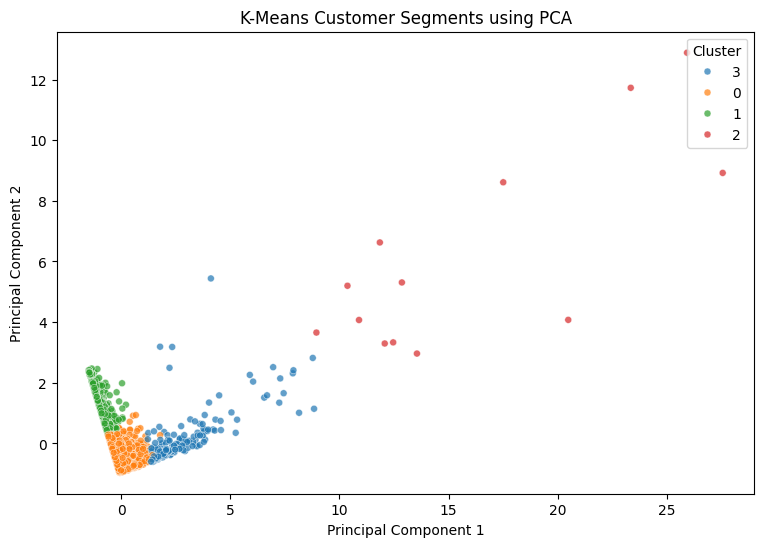

In [26]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["KMeans_Cluster"].astype(str),
    palette="tab10",
    s=25,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Segments using PCA")
plt.legend(title="Cluster")
plt.show()


DBSCAN Vizualization

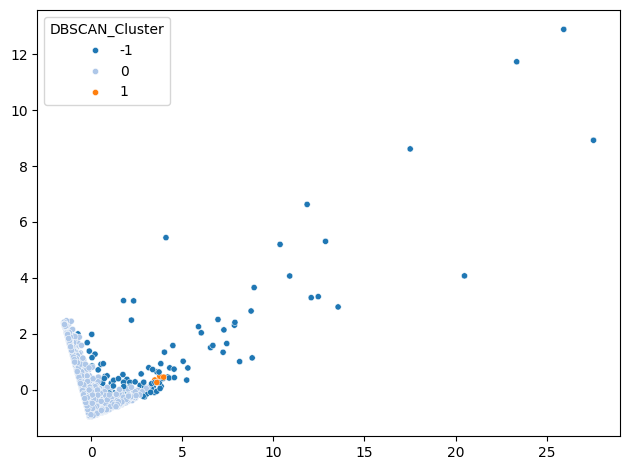

In [27]:
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["DBSCAN_Cluster"].astype(str),
    palette="tab20",
    s=20,
    )
axes[0].set_title("DBSCAN Clusters - PCA")
plt.tight_layout()
plt.show()


In [28]:
comparison = []

km_score = silhouette_score(
    X_scaled,
    rfm["KMeans_Cluster"],
    sample_size=min(2000, len(X_scaled)),
    random_state=42
)

comparison.append({
    "Algorithm": "K-Means",
    "Clusters": rfm["KMeans_Cluster"].nunique(),
    "Noise (%)": 0,
    "Silhouette": km_score
})

if "DBSCAN_Cluster" in rfm.columns:
    labels = rfm["DBSCAN_Cluster"].to_numpy()
    mask = labels != -1
    n_clusters = len(set(labels) - {-1})

    db_score = np.nan

    if n_clusters >= 2 and mask.sum() > n_clusters:
        db_score = silhouette_score(
            X_scaled[mask],
            labels[mask],
            sample_size=min(2000, mask.sum()),
            random_state=42
        )

    comparison.append({
        "Algorithm": "DBSCAN",
        "Clusters": n_clusters,
        "Noise (%)": round(100 * (~mask).mean(), 2),
        "Silhouette": db_score
    })

display(pd.DataFrame(comparison).round(3))



,Algorithm,Clusters,Noise (%),Silhouette
0,K-Means,4,0.00,0.616
1,DBSCAN,2,2.47,0.683
